# 03 - SMOTE experiments

SMOTE is a pipeline step (`imblearn.pipeline.Pipeline`), so it is refitted on each training fold and **skipped at prediction time**: validation and test rows are never oversampled.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from src.config import load_config
cfg = load_config()
M = cfg.path("paths", "metrics_dir"); F = cfg.path("paths", "figures_dir")
pd.set_option("display.precision", 4); pd.set_option("display.width", 200)
def show(name): display(Image(filename=str(F / name)))

In [2]:
from src.data.loader import load_split
from src.models.common import build_pipeline
from sklearn.dummy import DummyClassifier
X_tr, X_te, y_tr, y_te = load_split(cfg)
pipe = build_pipeline(DummyClassifier(), cfg, smote=True)
Xt, yt = X_tr, y_tr
for name, step in pipe.steps[:-1]:
    if hasattr(step, 'fit_resample'):
        Xt, yt = step.fit_resample(Xt, yt)
    else:
        Xt = step.fit_transform(Xt, yt)
print('training rows before SMOTE:', len(X_tr), 'positives:', int(y_tr.sum()))
print('training rows after  SMOTE:', len(Xt), 'positives:', int(yt.sum()))
pipe.fit(X_tr, y_tr); print('prediction rows (test):', len(pipe.predict_proba(X_te)), '= len(X_te) =', len(X_te))

training rows before SMOTE: 614 positives: 214
training rows after  SMOTE: 800 positives: 400
prediction rows (test): 154 = len(X_te) = 154


## Model | SMOTE | Precision | Recall | F1 | ROC-AUC | PR-AUC
CV columns: training-set CV at threshold 0.5. Test columns: held-out set at threshold 0.5.

In [3]:
sm = pd.read_csv(M / 'smote_comparison.csv')
sm[['model','smote','cv_precision@0.5','cv_recall@0.5','cv_f1@0.5','cv_roc_auc','cv_pr_auc','test_precision@0.5','test_recall@0.5','test_f1@0.5','test_roc_auc','test_pr_auc']]

,model,smote,cv_precision@0.5,cv_recall@0.5,cv_f1@0.5,cv_roc_auc,cv_pr_auc,test_precision@0.5,test_recall@0.5,test_f1@0.5,test_roc_auc,test_pr_auc
0,LogReg (default),False,0.7523,0.5735,0.6461,0.8425,0.7406,0.6000,0.5000,0.5455,0.8130,0.6733
1,LogReg (default),True,0.6524,0.7181,0.6798,0.8409,0.7390,0.6364,0.5185,0.5714,0.8113,0.6758
2,RandomForest (default),False,0.6922,0.5798,0.6263,0.8250,0.7182,0.6667,0.5556,0.6061,0.8133,0.6983
3,RandomForest (default),True,0.6455,0.6841,0.6607,0.8232,0.7055,0.6207,0.6667,0.6429,0.8172,0.7070
4,XGBoost (tuned),False,0.6758,0.5999,0.6316,0.8220,0.7126,0.6400,0.5926,0.6154,0.8200,0.7061
5,XGBoost (tuned),True,0.6411,0.6886,0.6607,0.8211,0.7073,0.6600,0.6111,0.6346,0.8224,0.7146
6,ExtraTrees (tuned),False,0.7880,0.4706,0.5846,0.8454,0.7541,0.6000,0.5556,0.5769,0.8139,0.6817
7,ExtraTrees (tuned),True,0.6458,0.7399,0.6860,0.8454,0.7472,0.6200,0.5741,0.5962,0.8254,0.7068
8,CatBoost (tuned),False,0.7148,0.5595,0.6231,0.8404,0.7453,0.6591,0.5370,0.5918,0.8207,0.6821
9,CatBoost (tuned),True,0.6382,0.7555,0.6893,0.8372,0.7365,0.6591,0.5370,0.5918,0.8111,0.6928


## SMOTE effect (SMOTE minus no-SMOTE)
`pp` = percentage points; `rel_pct` = relative change.

In [4]:
eff = pd.read_csv(M / 'smote_effect.csv'); eff

,model,cv_recall@0.5_delta_pp,cv_recall@0.5_rel_pct,cv_f1@0.5_delta_pp,cv_pr_auc_delta,cv_roc_auc_delta,cv_brier_delta,test_recall@0.5_delta_pp,test_f1@0.5_delta_pp,test_f1@tuned_delta_pp
0,LogReg (default),14.4666,25.2269,3.3750,-0.0016,-1.5236e-03,0.0101,1.8519,2.5974,-1.6596
1,RandomForest (default),10.4245,17.9781,3.4342,-0.0127,-1.8300e-03,0.0046,11.1111,3.6797,0.0000
2,XGBoost (tuned),8.8741,14.7929,2.9079,-0.0053,-8.8870e-04,0.0077,1.8519,1.9231,1.5873
3,ExtraTrees (tuned),26.9324,57.2280,10.1337,-0.0069,3.9221e-05,0.0056,1.8519,1.9231,3.1023
4,CatBoost (tuned),19.6013,35.0356,6.6235,-0.0088,-3.1631e-03,0.0083,0.0000,0.0000,-2.0632
5,Stacking (tuned),3.5733,6.3330,1.5183,-0.0012,2.7501e-04,-0.0007,5.5556,2.8582,1.1432
6,XGBoost (default),6.0797,10.1348,1.6147,0.0035,4.4611e-03,0.0030,0.0000,-0.6263,-2.5063
7,ExtraTrees (default),19.5866,37.6152,7.5085,-0.0065,-9.3669e-04,0.0034,-1.8519,-1.8868,0.0000
8,CatBoost (default),6.9989,11.6056,2.6853,-0.0042,9.1178e-04,0.0036,3.7037,4.0816,-0.1943
9,Stacking (default),3.4182,6.0757,1.9508,-0.0015,1.1771e-03,-0.0013,-1.8519,-3.0479,-1.5034


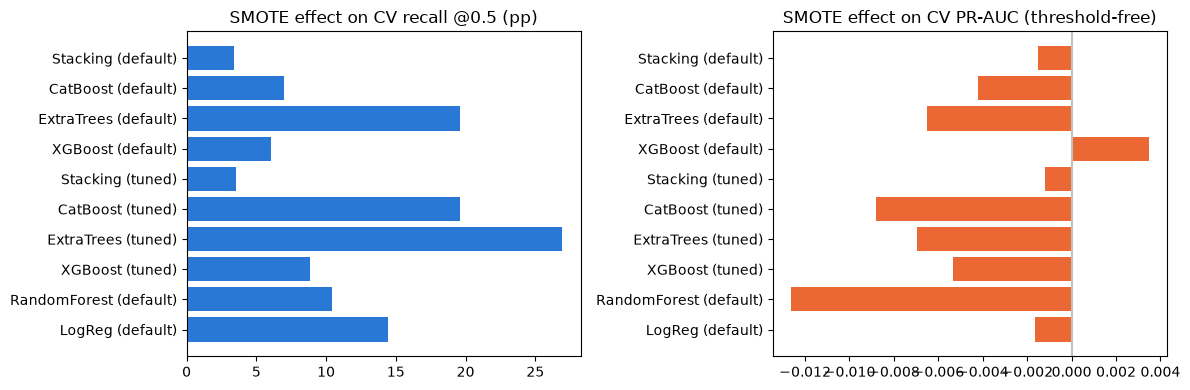

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].barh(eff.model, eff['cv_recall@0.5_delta_pp'], color='#2a78d6'); ax[0].axvline(0, color='#c3c2b7')
ax[0].set_title('SMOTE effect on CV recall @0.5 (pp)')
ax[1].barh(eff.model, eff['cv_pr_auc_delta'], color='#eb6834'); ax[1].axvline(0, color='#c3c2b7')
ax[1].set_title('SMOTE effect on CV PR-AUC (threshold-free)'); plt.tight_layout(); plt.show()

**Reading the result:** compare the recall change at a fixed 0.5 threshold with the change in threshold-free ranking quality (PR-AUC / ROC-AUC). If recall rises while PR-AUC does not, SMOTE is mainly shifting predicted probabilities upward - an effect a lower threshold reproduces without synthetic data.

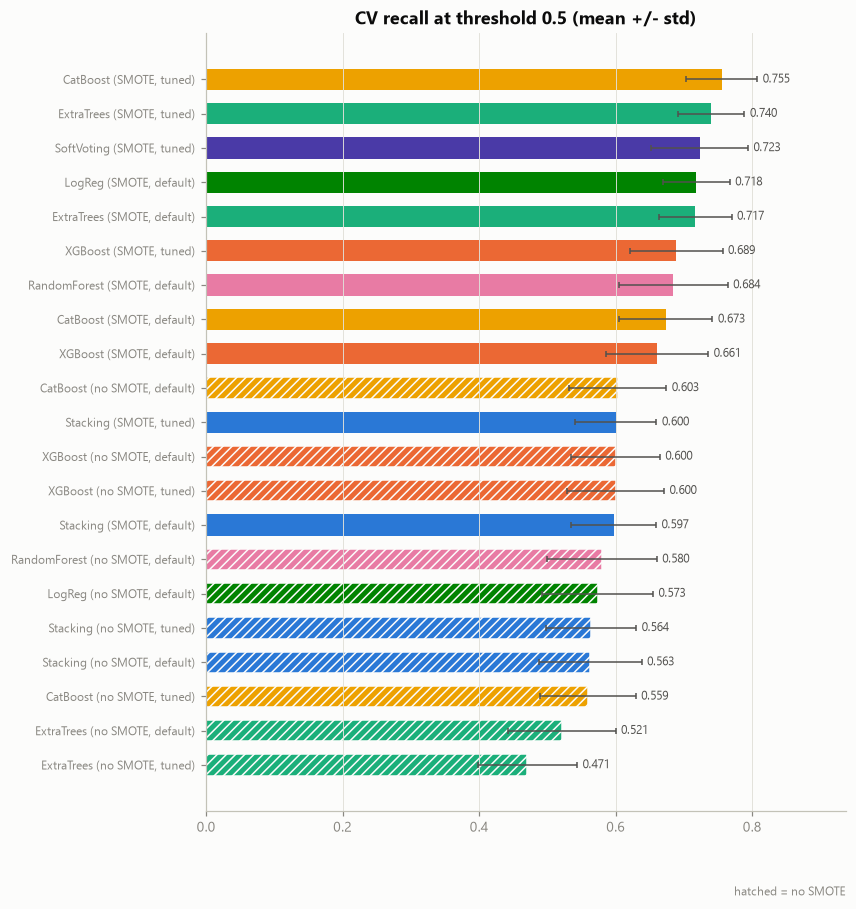

In [6]:
show('cv_recall_comparison.png')